# Batch 4: MATLAB-style validation tests (System Identification Toolbox style)
The same checks MATLAB's System Identification Toolbox shows, for every model, on the **unseen test flights**:

| MATLAB command | what it shows | here |
|---|---|---|
| `compare` | measured vs model, with **Fit %** | section 2 |
| (Ghezzi) | **VAF %** | section 2 |
| `resid` | are the leftover errors random? (auto- and cross-correlation with 99 % band) | section 3 |
| `present` | constants **± 1 standard deviation** | section 4 |
| `pzmap`, `step`, `bode` | poles, step response, frequency response | section 5 |

Two cases (separate models, see the both-signals notebook):
- **motors off** (impulse): train impulse_1 to impulse_4, test impulse_5
- **hover** (doublet): train doublet_1 to doublet_5, test doublet_6

Models: equation with sim-fit constants, equation with inverse-PINN constants, and for hover also the PINC and the plain NN (seed 0, same training as Batch 3).

## 0. Setup

In [1]:
import numpy as np, pandas as pd, torch, time, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy import signal
torch.set_num_threads(4)
D = '../data/1dof/'
FL = pd.read_csv(D + 'flights_1dof.csv').set_index('file')
TAU = 0.02      # delay [s]
DT = 0.02       # evaluation grid [s] (same as the PINC step)
CASES = {'motors off': dict(train=[f'impulse_{i}.csv' for i in range(1, 5)], test='impulse_5.csv'),
         'hover': dict(train=[f'doublet_{i}.csv' for i in range(1, 6)], test='doublet_6.csv')}

## 1. Data, physics and models

In [2]:
def load(name):
    r = FL.loc[name]; df = pd.read_csv(D + name)
    if name.startswith('impulse'):
        end = r.inj_start_s - 0.1 + 6.0
    else:
        after = df[df.t > r.inj_start_s + 0.7]; end = after.t[after.M.abs() > 0.12].iloc[0] - 0.05
    f = df[(df.t >= r.inj_start_s - 0.1 - TAU) & (df.t < end)].reset_index(drop=True)
    f['t'] = f.t - f.t[0] - TAU
    return f

def steps(f):
    t = np.arange(0, f.t.iloc[-1] - DT, DT)
    th = np.interp(t, f.t, f.theta); q = np.interp(t, f.t, f.q)
    M = np.array([np.mean(np.interp(np.linspace(ti, ti + DT, 6)[:-1] - TAU, f.t, f.M)) for ti in t])
    return t, th, q, M

def accel(theta, q, M, p):
    return -2 * p['xi'] * p['wn'] * q - p['wn']**2 * (theta - p['th0']) + p['mu'] * M

def ivp_model(p):
    # equation as a step function over one DT (M held)
    def step(th, q, M):
        y = solve_ivp(lambda t, z: [z[1], accel(z[0], z[1], M, p)], (0, DT), [th, q], max_step=DT / 5).y[:, -1]
        return y[0], y[1]
    return step

def run_open(step, g):
    # simulation: chain from the first measured state (MATLAB compare default)
    t, th, q, M = g; a, b = th[0], q[0]; out = [a]
    for k in range(len(t) - 1):
        a, b = step(a, b, M[k]); out.append(a)
    return np.array(out)

def run_one_step(step, g):
    # 1-step-ahead prediction: restart from the measured state every step
    t, th, q, M = g; out = [th[0]]
    for k in range(len(t) - 1): out.append(step(th[k], q[k], M[k])[0])
    return np.array(out)

### Sim-fit constants again, now with their uncertainty
`least_squares` also returns the Jacobian J (how much each residual moves when a constant moves). MATLAB's `present` uses the same idea:
covariance = s^2 (J^T J)^-1, where s^2 = residual variance. The square root of the diagonal is the ± value.

In [3]:
def sim_fit_with_std(names):
    keys = ['wn', 'xi', 'mu', 'th0']
    G = [steps(load(n)) for n in names]
    def residual(v):
        p = dict(zip(keys, v))
        return np.concatenate([run_open(ivp_model(p), g) - g[1] for g in G])
    r = least_squares(residual, [3.8, 0.15, 120, 0], bounds=([0.5, 0, 0, -0.5], [20, 2, 2000, 0.5]))
    s2 = np.sum(r.fun**2) / (len(r.fun) - len(keys))
    cov = s2 * np.linalg.inv(r.jac.T @ r.jac)
    return dict(zip(keys, r.x)), dict(zip(keys, np.sqrt(np.diag(cov))))

fits = {}
for case, cfg in CASES.items():
    t0 = time.time(); p, sd = sim_fit_with_std(cfg['train']); fits[case] = (p, sd)
    print(case, {k: f'{p[k]:.4f} ± {sd[k]:.4f}' for k in p}, f'({time.time() - t0:.0f} s)')

motors off {'wn': '4.0834 ± 0.0071', 'xi': '0.2130 ± 0.0025', 'mu': '78.6020 ± 0.7242', 'th0': '-0.0017 ± 0.0005'} (13 s)


hover {'wn': '3.8608 ± 0.0723', 'xi': '0.1365 ± 0.0307', 'mu': '182.8074 ± 9.0935', 'th0': '-0.1561 ± 0.0127'} (6 s)


### Inverse-PINN constants (from the Batch 2 notebooks)
For the PINN the ± is the spread (std) over the training flights, one PINN per flight.

In [4]:
def pinn_consts(csv, col, th0):
    c = pd.read_csv(csv, index_col=0)
    p = dict(wn=float(c.loc['wn [rad/s]', col]), xi=float(c.loc['xi [-]', col]), mu=float(c.loc['mu [rad/s^2]', col]), th0=th0)
    spread = dict(x.split(' ') for x in c.loc['spread over flights (std)', col].split(', '))
    return p, {k: float(v) for k, v in spread.items()}
pinn = {'motors off': pinn_consts('../results/batch1_2_constants.csv', 'Inverse PINN (mean of 4)', 0.0),
        'hover': pinn_consts('../results/batch1_2_doublet_constants.csv', 'Inverse PINN (mean of 5)', -0.1506)}
pinn

{'motors off': ({'wn': 4.035130262374878,
   'xi': 0.16108505055308342,
   'mu': 65.48466491699219,
   'th0': 0.0},
  {'wn': 0.012, 'xi': 0.005, 'mu': 2.5}),
 'hover': ({'wn': 3.843431568145752,
   'xi': 0.10543726608157158,
   'mu': 159.92521057128906,
   'th0': -0.1506},
  {'wn': 0.295, 'xi': 0.059, 'mu': 20.6})}

### PINC and plain NN for hover (seed 0, same training as Batch 3)
For the MATLAB-style training plots we hold one flight out as **validation**: train doublet_1 to doublet_4, validation doublet_5, test doublet_6.

In [5]:
def mlp(n_in, n_out, width=32, depth=3):
    layers, n = [], n_in
    for _ in range(depth): layers += [torch.nn.Linear(n, width), torch.nn.Tanh()]; n = width
    return torch.nn.Sequential(*layers, torch.nn.Linear(n, n_out))
col = lambda x: torch.tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)
S = dict(th=0.3, q=4.0, M=0.06)
def pinc_model(net):
    def step(th, q, M, dt):
        o = net(torch.cat([th / S['th'], q / S['q'], M / S['M'], dt / DT], 1)); return S['th'] * o[:, :1], S['q'] * o[:, 1:2]
    return step
def pairs(names):
    G = [steps(load(n)) for n in names]
    return [col(np.concatenate([g[i][:-1] for g in G])) for i in (1, 2, 3)] + [col(np.concatenate([g[i][1:] for g in G])) for i in (1, 2)]
def train_pinc(names, p, val=None, test=None, seed=0, epochs=20000, lr=1e-3, w_phys=1.0, n_col=2000):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    G = [steps(load(n)) for n in names]
    th0 = col(np.concatenate([g[1][:-1] for g in G])); q0 = col(np.concatenate([g[2][:-1] for g in G]))
    th1 = col(np.concatenate([g[1][1:] for g in G])); q1 = col(np.concatenate([g[2][1:] for g in G])); M0 = col(np.concatenate([g[3][:-1] for g in G]))
    net = mlp(4, 2); step = pinc_model(net)
    opt = torch.optim.Adam(net.parameters(), lr=lr); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    sets = {'train': (th0, q0, M0, th1, q1)}
    if val: sets['validation'] = tuple(pairs(val))
    if test: sets['test'] = tuple(pairs(test))
    perf = []
    for e in range(epochs):
        if e % 200 == 0 or e == epochs - 1:
            with torch.no_grad():
                row = [e]
                for k, (a_, b_, m_, a1, b1) in sets.items():
                    x, y = step(a_, b_, m_, torch.full_like(a_, DT)); row.append(((((x - a1) / S['th'])**2).mean() + (((y - b1) / S['q'])**2).mean()).item())
                perf.append(row)
        a, b = step(th0, q0, M0, torch.full_like(th0, DT)); data = (((a - th1) / S['th'])**2).mean() + (((b - q1) / S['q'])**2).mean()
        a, b = step(th0, q0, M0, torch.zeros_like(th0)); start = (((a - th0) / S['th'])**2).mean() + (((b - q0) / S['q'])**2).mean()
        physics = torch.tensor(0.0)
        if w_phys > 0:
            zt = col(rng.uniform(-0.35, 0.35, n_col)); zq = col(rng.uniform(-4, 4, n_col)); zM = col(rng.uniform(-0.06, 0.06, n_col))
            dt = col(rng.uniform(0, DT, n_col)).requires_grad_(True); a, b = step(zt, zq, zM, dt)
            da = torch.autograd.grad(a, dt, torch.ones_like(a), create_graph=True)[0]; db = torch.autograd.grad(b, dt, torch.ones_like(b), create_graph=True)[0]
            physics = (((da - b) / S['q'])**2).mean() + (((db - accel(a, b, zM, p)) / (S['q'] / DT))**2).mean()
            a, b = step(zt, zq, zM, torch.zeros_like(zt)); start = start + (((a - zt) / S['th'])**2).mean() + (((b - zq) / S['q'])**2).mean()
        loss = data + start + w_phys * physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    def as_numpy_step(th, q, M):
        with torch.no_grad():
            a, b = step(col([th]), col([q]), col([M]), col([DT])); return a.item(), b.item()
    as_numpy_step.perf = pd.DataFrame(perf, columns=['epoch'] + list(sets))
    as_numpy_step.sets = sets; as_numpy_step.torch_step = step
    return as_numpy_step
nets = {}
for label, wp in [('PINC', 1.0), ('plain NN', 0.0)]:
    t0 = time.time(); nets[label] = train_pinc([f'doublet_{i}.csv' for i in range(1, 5)], pinn['hover'][0], val=['doublet_5.csv'], test=['doublet_6.csv'], w_phys=wp); print(label, f'{time.time() - t0:.0f} s')

PINC 104 s


plain NN 29 s


## 2. `compare`: Fit % and VAF on the unseen flight
**Fit %** (MATLAB) = 100 (1 - ||y - y_model|| / ||y - mean(y)||). 100 % = perfect, 0 % = no better than a flat line at the mean. It is stricter than VAF: VAF 99 % is about Fit 90 %.

**VAF %** (Ghezzi) = 100 (1 - var(y - y_model) / var(y)).

Two versions, like MATLAB: **simulation** (chain from the start, the hard test) and **1-step prediction** (restart from the measured state each step, the easy test).

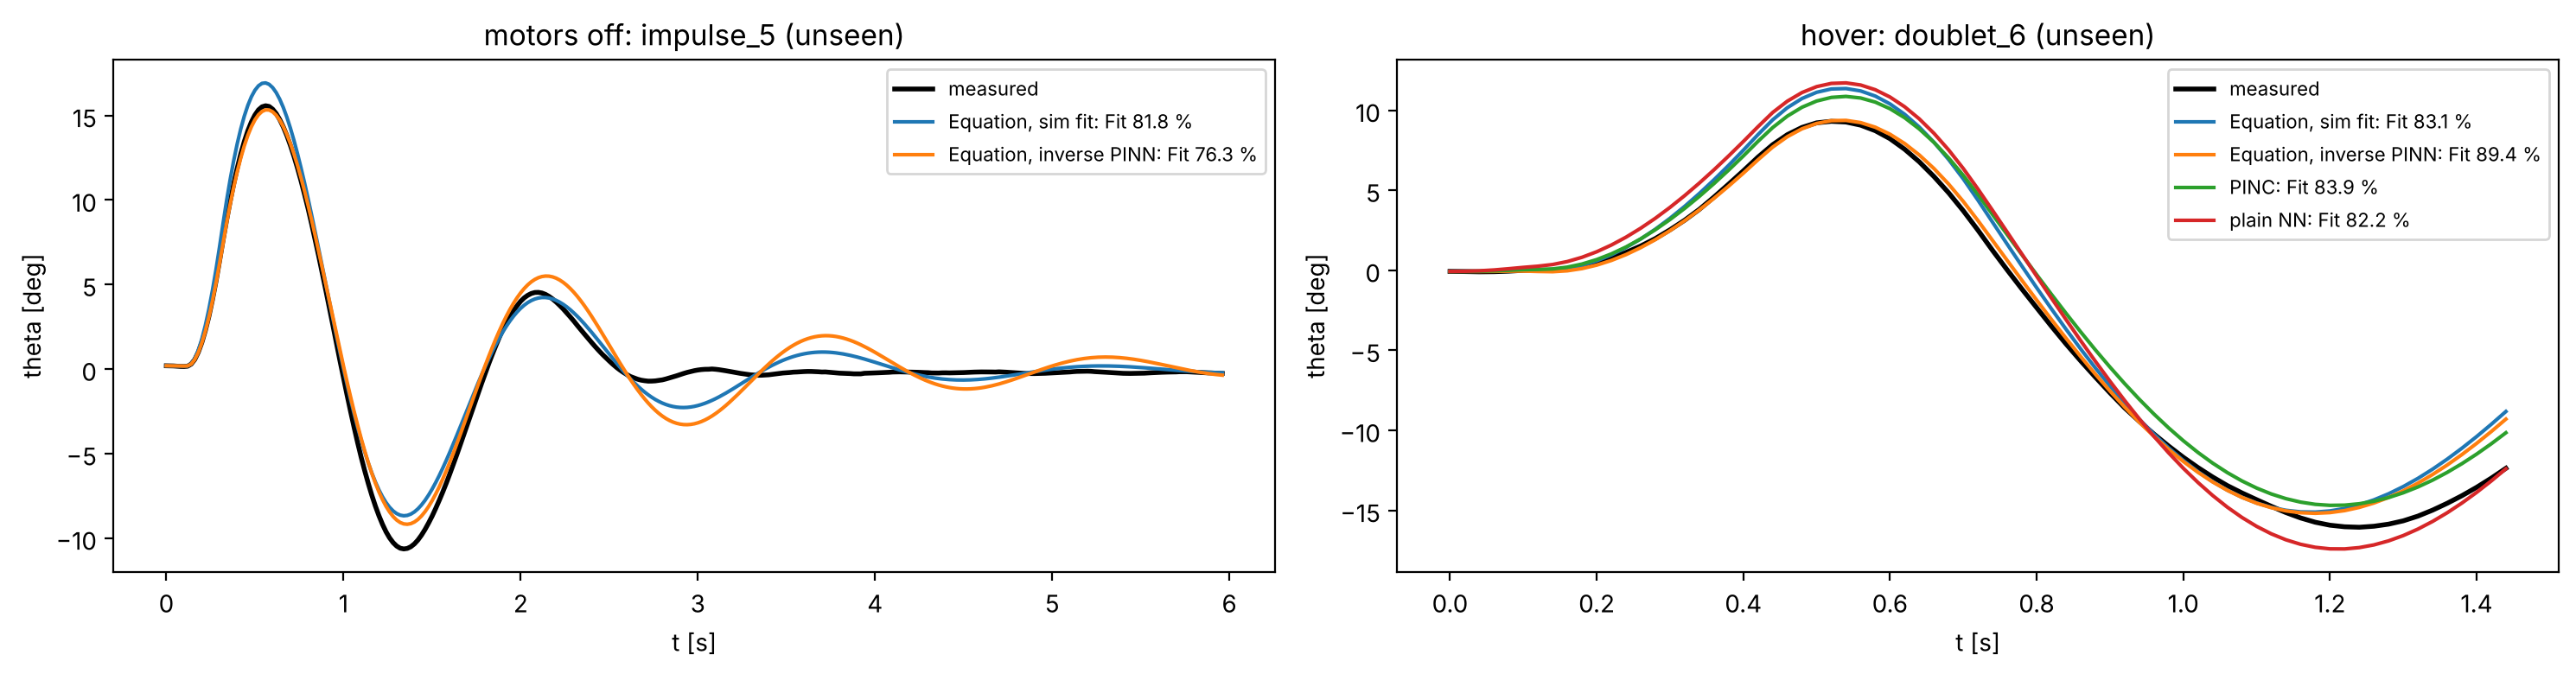

Fit % (simulation)  VAF % (simulation)  \
motors off Equation, sim fit                    81.78               97.02   
           Equation, inverse PINN               76.34               94.66   
hover      Equation, sim fit                    83.07               98.66   
           Equation, inverse PINN               89.38               99.09   
           PINC                                 83.88               99.34   
           plain NN                             82.16               97.35   

                                   Fit % (1-step)  
motors off Equation, sim fit                99.84  
           Equation, inverse PINN           99.83  
hover      Equation, sim fit                99.84  
           Equation, inverse PINN           99.83  
           PINC                             99.84  
           plain NN                         99.82

In [6]:
fitp = lambda y, yh: 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - y.mean()))
vaf = lambda y, yh: max(1 - np.var(y - yh) / np.var(y), 0) * 100
models = {case: {'Equation, sim fit': ivp_model(fits[case][0]), 'Equation, inverse PINN': ivp_model(pinn[case][0])} for case in CASES}
models['hover'].update(nets)
sims, rows = {}, {}
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, (case, cfg) in zip(ax, CASES.items()):
    g = steps(load(cfg['test'])); a.plot(g[0], np.degrees(g[1]), 'k', lw=2, label='measured')
    for label, st in models[case].items():
        ys = run_open(st, g); y1 = run_one_step(st, g); sims[(case, label)] = (g, ys)
        rows[(case, label)] = [fitp(g[1], ys), vaf(g[1], ys), fitp(g[1], y1)]
        a.plot(g[0], np.degrees(ys), label=f'{label}: Fit {fitp(g[1], ys):.1f} %')
    a.set(title=f"{case}: {cfg['test'].replace('.csv', '')} (unseen)", xlabel='t [s]', ylabel='theta [deg]'); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../figures/batch4_compare.png', dpi=120, bbox_inches='tight'); plt.show()
t_compare = pd.DataFrame(rows, index=['Fit % (simulation)', 'VAF % (simulation)', 'Fit % (1-step)']).T.round(2)
t_compare.to_csv('../results/batch4_compare.csv'); t_compare

## 3. `resid`: are the leftover errors random?
Residual e = measured - model (simulation). A good model leaves only random noise, so:
- **Autocorrelation of e** (top): bars at lag > 0 should stay **inside the 99 % band** (± 2.58 / sqrt(N)). Bars outside = the model missed some dynamics (a pattern is left in the error).
- **Cross-correlation of e with the input M** (bottom): should stay inside the band too. Bars outside = part of the input's effect is not explained (e.g. wrong gain mu or wrong delay). Bars at negative lags only mean feedback, not a model error.

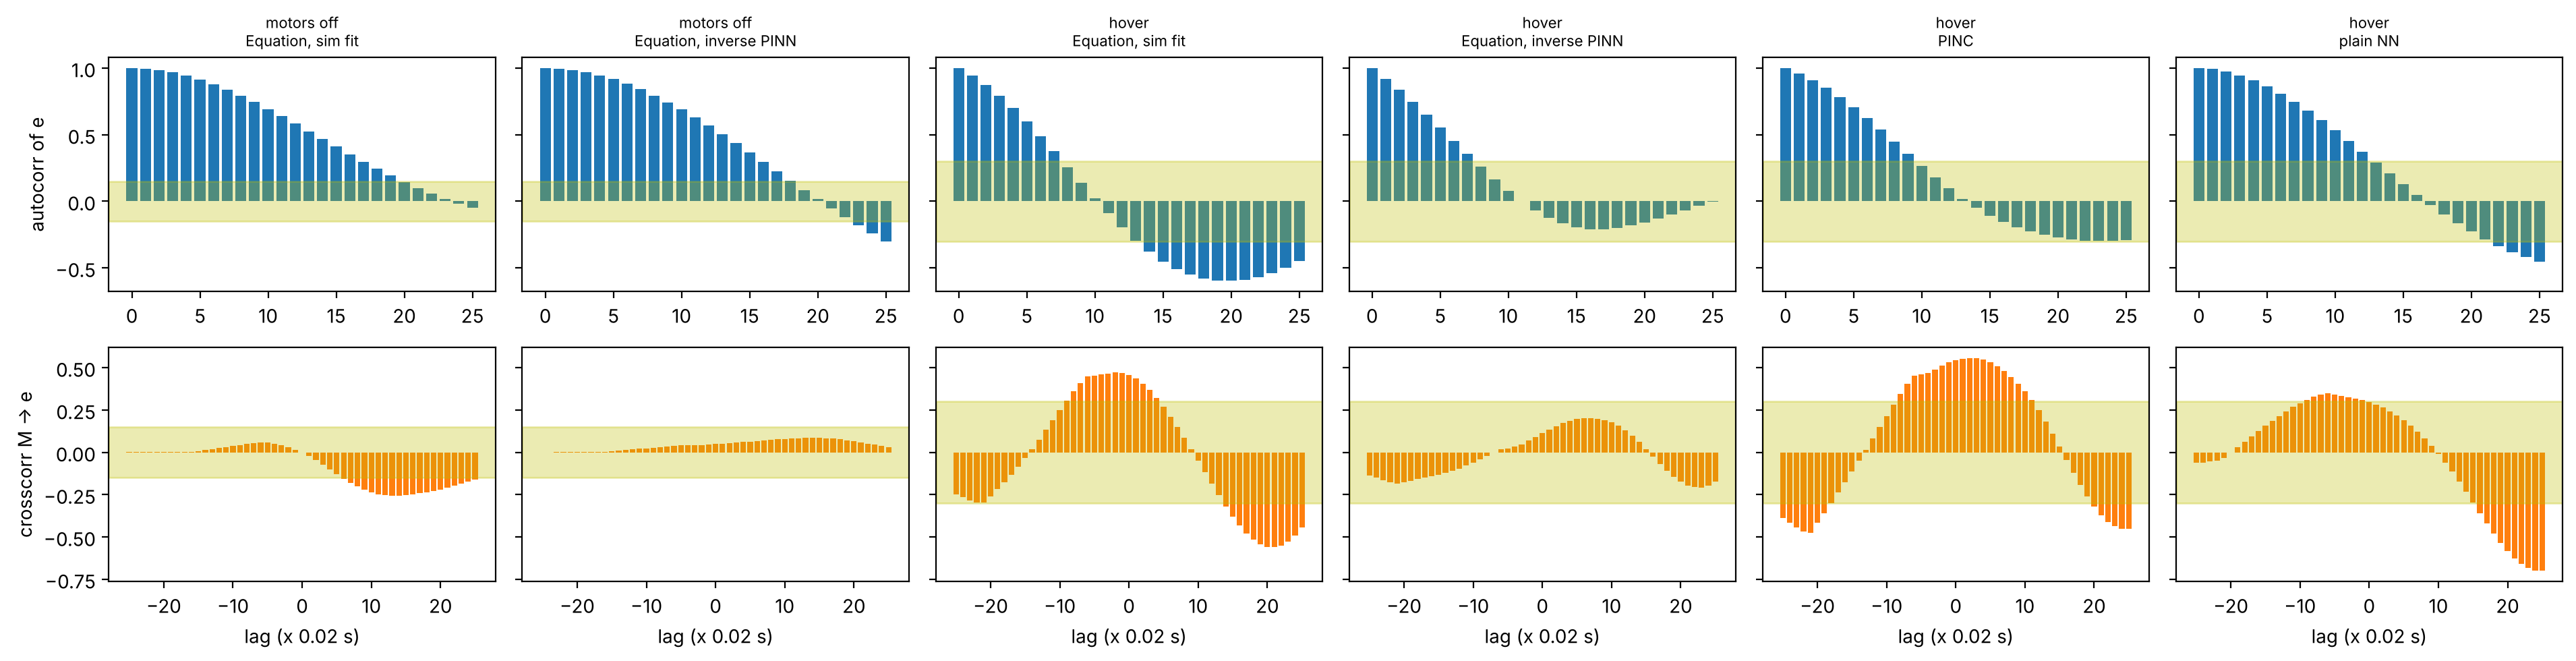

autocorr lags outside band (of 25)  \
motors off Equation, sim fit                                       19   
           Equation, inverse PINN                                  21   
hover      Equation, sim fit                                       19   
           Equation, inverse PINN                                   7   
           PINC                                                     9   
           plain NN                                                16   

                                   crosscorr lags >= 0 outside band (of 26)  \
motors off Equation, sim fit                                             20   
           Equation, inverse PINN                                         0   
hover      Equation, sim fit                                             17   
           Equation, inverse PINN                                         0   
           PINC                                                          18   
           plain NN                                                      10   

                                   N samples  
motors off Equation, sim fit             299  
           Equation, inverse PINN        299  
hover      Equation, sim fit              73  
           Equation, inverse PINN         73  
           PINC                           73  
           plain NN                       73

In [7]:
def xcorr(a, b, maxlag):
    a = a - a.mean(); b = b - b.mean(); n = len(a); den = np.sqrt(np.sum(a**2) * np.sum(b**2))
    return np.array([np.sum(a[max(0, -k):n - max(0, k)] * b[max(0, k):n - max(0, -k)]) / den for k in range(-maxlag, maxlag + 1)])
LAG = 25
fig, ax = plt.subplots(2, len(sims), figsize=(3.2 * len(sims), 5), sharey='row')
res_rows = {}
for j, ((case, label), (g, ys)) in enumerate(sims.items()):
    e = g[1] - ys; N = len(e); band = 2.58 / np.sqrt(N); lags = np.arange(-LAG, LAG + 1)
    ra = xcorr(e, e, LAG); rx = xcorr(g[3], e, LAG)          # rx at lag k: input k steps before the error
    ax[0, j].bar(lags[LAG:], ra[LAG:], width=0.8); ax[0, j].axhspan(-band, band, color='y', alpha=0.3)
    ax[1, j].bar(lags, rx, width=0.8, color='C1'); ax[1, j].axhspan(-band, band, color='y', alpha=0.3)
    ax[0, j].set_title(f'{case}\n{label}', fontsize=8); ax[1, j].set_xlabel('lag (x 0.02 s)')
    res_rows[(case, label)] = [int(np.sum(np.abs(ra[LAG + 1:]) > band)), int(np.sum(np.abs(rx[LAG:]) > band)), N]
ax[0, 0].set_ylabel('autocorr of e'); ax[1, 0].set_ylabel('crosscorr M -> e')
plt.tight_layout(); plt.savefig('../figures/batch4_resid.png', dpi=110, bbox_inches='tight'); plt.show()
t_resid = pd.DataFrame(res_rows, index=['autocorr lags outside band (of 25)', 'crosscorr lags >= 0 outside band (of 26)', 'N samples']).T
t_resid.to_csv('../results/batch4_resid.csv'); t_resid

## 4. `present`: constants ± 1 standard deviation
- Sim fit: ± from the Jacobian (MATLAB's way).
- Inverse PINN: ± = spread over the training flights (one PINN per flight).
Small ± relative to the value = the data pins the constant down well.

In [8]:
rows = {}
for case in CASES:
    for label, (p, sd) in [('Equation, sim fit', fits[case]), ('Equation, inverse PINN', pinn[case])]:
        rows[(case, label)] = [f"{p[k]:.3f} ± {sd.get(k, float('nan')):.3f}" for k in ['wn', 'xi', 'mu']]
t_present = pd.DataFrame(rows, index=['wn [rad/s]', 'xi [-]', 'mu [rad/s^2]']).T
t_present.to_csv('../results/batch4_present.csv'); t_present

wn [rad/s]         xi [-]  \
motors off Equation, sim fit       4.083 ± 0.007  0.213 ± 0.003   
           Equation, inverse PINN  4.035 ± 0.012  0.161 ± 0.005   
hover      Equation, sim fit       3.861 ± 0.072  0.136 ± 0.031   
           Equation, inverse PINN  3.843 ± 0.295  0.105 ± 0.059   

                                       mu [rad/s^2]  
motors off Equation, sim fit         78.602 ± 0.724  
           Equation, inverse PINN    65.485 ± 2.500  
hover      Equation, sim fit        182.807 ± 9.093  
           Equation, inverse PINN  159.925 ± 20.600

## 5. `pzmap`, `step`, `bode` for the equation models
Transfer function from M to theta (deviation from rest), with the 0.02 s delay:

G(s) = mu e^(-0.02 s) / (s^2 + 2 xi wn s + wn^2)

- **Poles** s = -xi wn ± j wn sqrt(1 - xi^2): further left = dies out faster; higher up = swings faster.
- **Step response** to M = 0.01: final angle = 0.01 mu / wn^2, overshoot depends on xi.
- **Bode**: peak at about wn (resonance), height set by xi; above wn the gain falls 40 dB per decade.

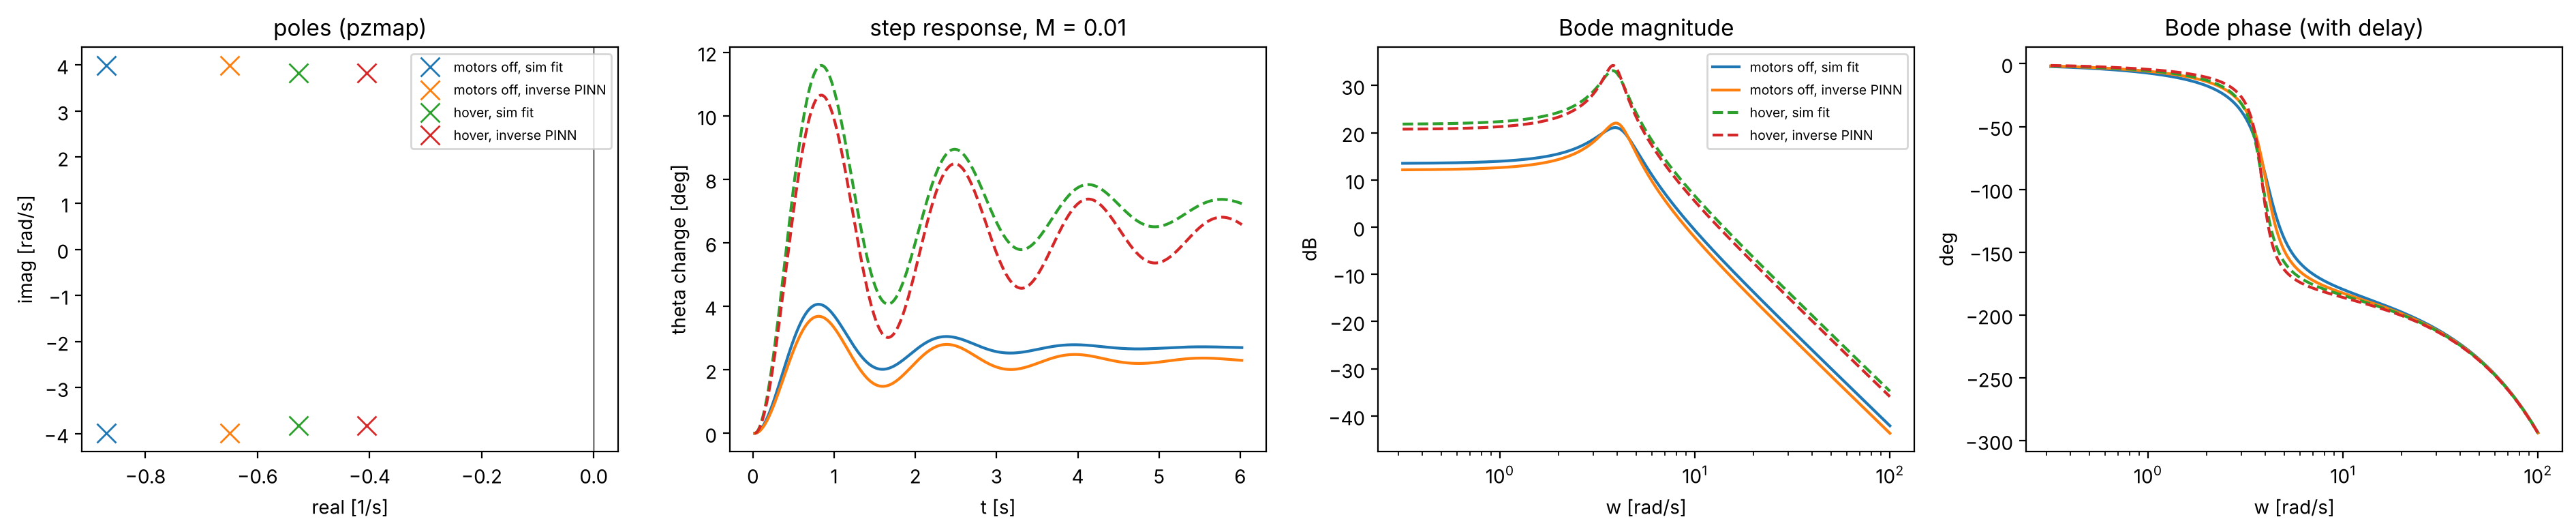

,poles,step final angle for M=0.01 [deg],overshoot [%],resonance peak at [rad/s]
"motors off, sim fit",-0.870 ± 3.990j,2.700877,50.422945,3.893851
"motors off, inverse PINN",-0.650 ± 3.982j,2.304343,59.88405,3.92903
"hover, sim fit",-0.527 ± 3.825j,7.026854,64.865809,3.788195
"hover, inverse PINN",-0.405 ± 3.822j,6.202993,71.670021,3.800464


In [9]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
w = np.logspace(-0.5, 2, 400); prows = {}
for case, ls in [('motors off', '-'), ('hover', '--')]:
    for label, (p, _) in [('sim fit', fits[case]), ('inverse PINN', pinn[case])]:
        sys_ = signal.TransferFunction([p['mu']], [1, 2 * p['xi'] * p['wn'], p['wn']**2])
        poles = np.roots([1, 2 * p['xi'] * p['wn'], p['wn']**2]); name = f'{case}, {label}'
        ax[0].plot(poles.real, poles.imag, 'x', ms=10, label=name)
        ts, ys = signal.step(sys_, T=np.linspace(0, 6, 600)); ts = ts + TAU
        ax[1].plot(ts, np.degrees(0.01 * ys), ls, label=name)
        _, mag, ph = signal.bode(sys_, w); ph = ph - np.degrees(w * TAU)
        ax[2].semilogx(w, mag, ls, label=name); ax[3].semilogx(w, ph, ls, label=name)
        prows[name] = [f'{poles[0].real:.3f} ± {abs(poles[0].imag):.3f}j', 0.01 * p['mu'] / p['wn']**2 * 180 / np.pi,
                       100 * np.exp(-np.pi * p['xi'] / np.sqrt(1 - p['xi']**2)), p['wn'] * np.sqrt(1 - 2 * p['xi']**2) if p['xi'] < 0.707 else np.nan]
ax[0].axvline(0, color='k', lw=0.5); ax[0].set(title='poles (pzmap)', xlabel='real [1/s]', ylabel='imag [rad/s]'); ax[0].legend(fontsize=7)
ax[1].set(title='step response, M = 0.01', xlabel='t [s]', ylabel='theta change [deg]')
ax[2].set(title='Bode magnitude', xlabel='w [rad/s]', ylabel='dB'); ax[3].set(title='Bode phase (with delay)', xlabel='w [rad/s]', ylabel='deg')
ax[2].legend(fontsize=7); plt.tight_layout(); plt.savefig('../figures/batch4_poles_step_bode.png', dpi=110, bbox_inches='tight'); plt.show()
t_poles = pd.DataFrame(prows, index=['poles', 'step final angle for M=0.01 [deg]', 'overshoot [%]', 'resonance peak at [rad/s]']).T
t_poles.to_csv('../results/batch4_poles.csv'); t_poles.round(3)

## 6. Neural-network training plots (MATLAB Neural Net Toolbox style), PINC and plain NN
One-step error (state now -> state 0.02 s later) on the three data sets: **train** (doublet_1 to 4), **validation** (doublet_5), **test** (doublet_6).

### 6a. `plotperform`: training, validation and test error vs epoch
How to read: all three lines should go down together. If **train keeps falling but validation/test turn up**, the net is memorising (overfitting). The best epoch is where validation is lowest.

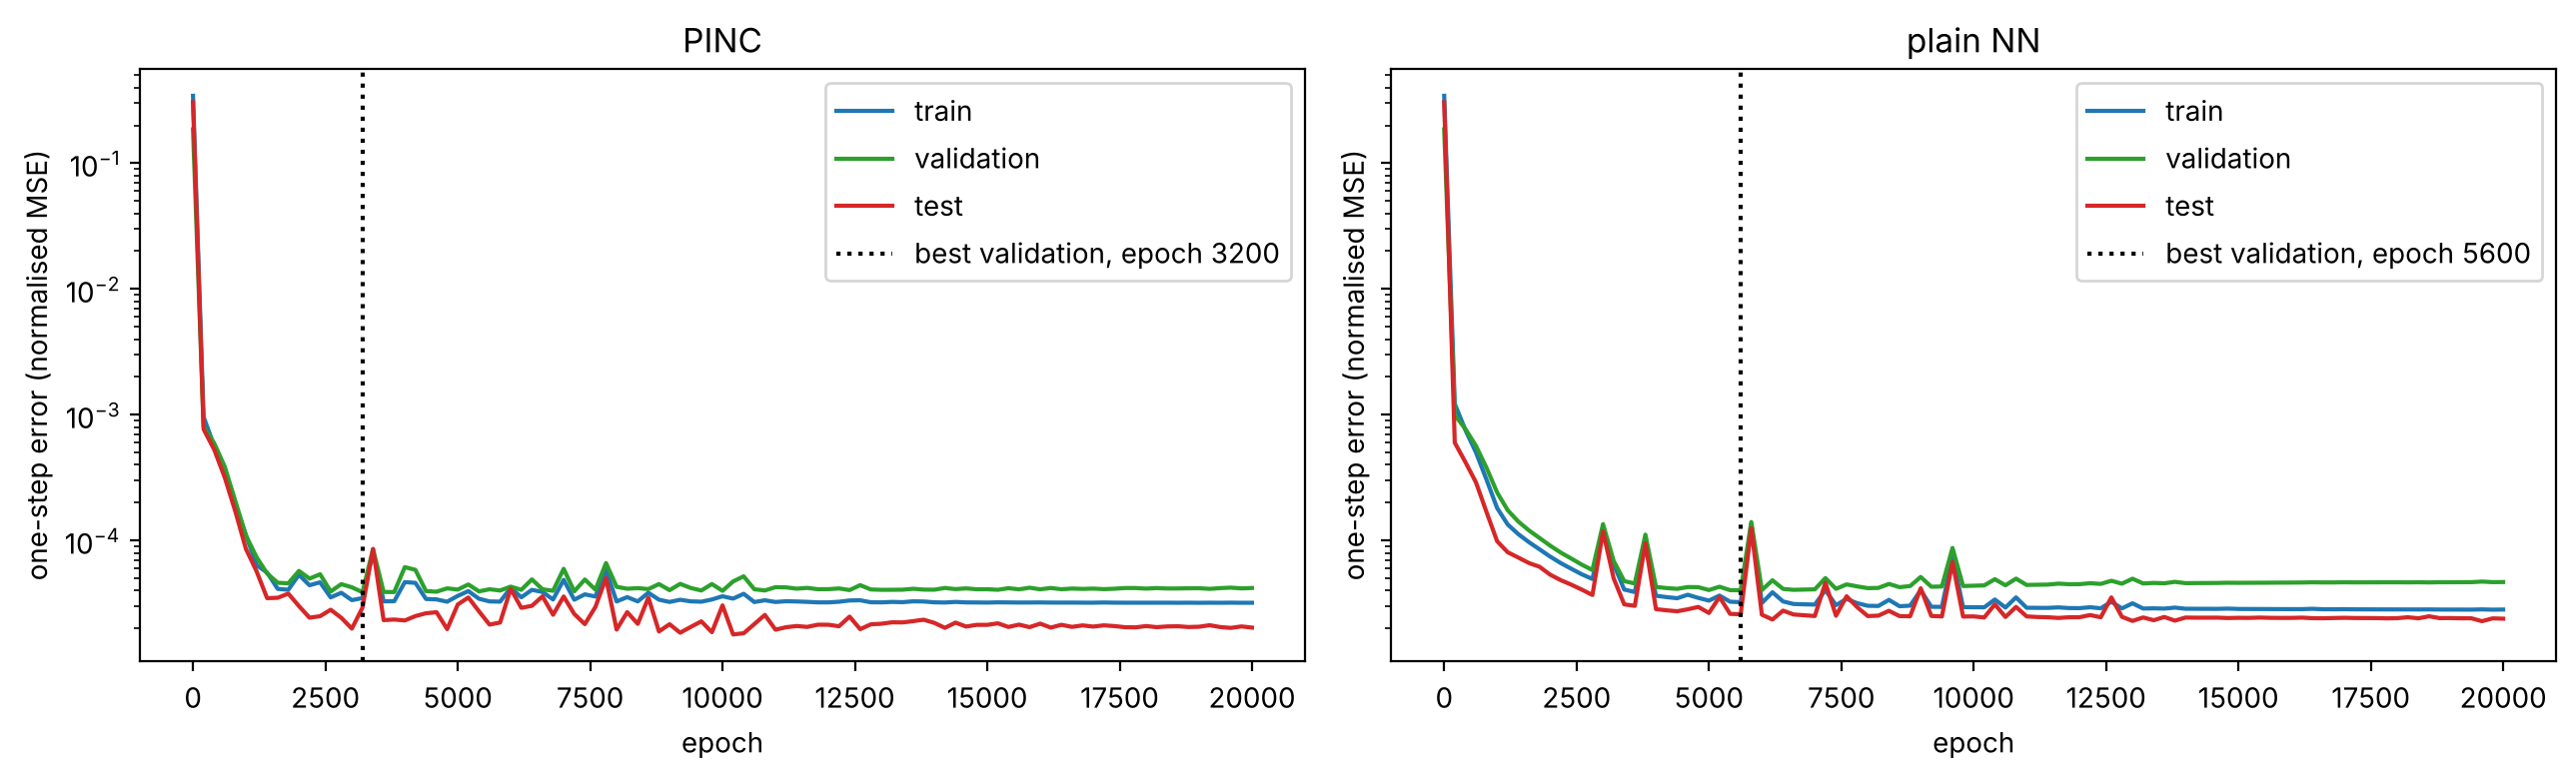

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, label in zip(ax, ['PINC', 'plain NN']):
    pf = nets[label].perf
    for k, c in [('train', 'C0'), ('validation', 'C2'), ('test', 'C3')]: a.semilogy(pf.epoch, pf[k], color=c, label=k)
    b = pf.validation.idxmin(); a.axvline(pf.epoch[b], color='k', ls=':', label=f'best validation, epoch {pf.epoch[b]}')
    a.set(title=label, xlabel='epoch', ylabel='one-step error (normalised MSE)'); a.legend()
plt.tight_layout(); plt.savefig('../figures/batch4_plotperform.png', dpi=110, bbox_inches='tight'); plt.show()

### 6b. `ploterrhist`: error histogram (the "pillars")
Each pillar counts how many one-step errors fall in that range; colours = train / validation / test. How to read: pillars should be **tall and narrow around zero** (the orange line). A wide spread or a peak away from zero means a systematic error.

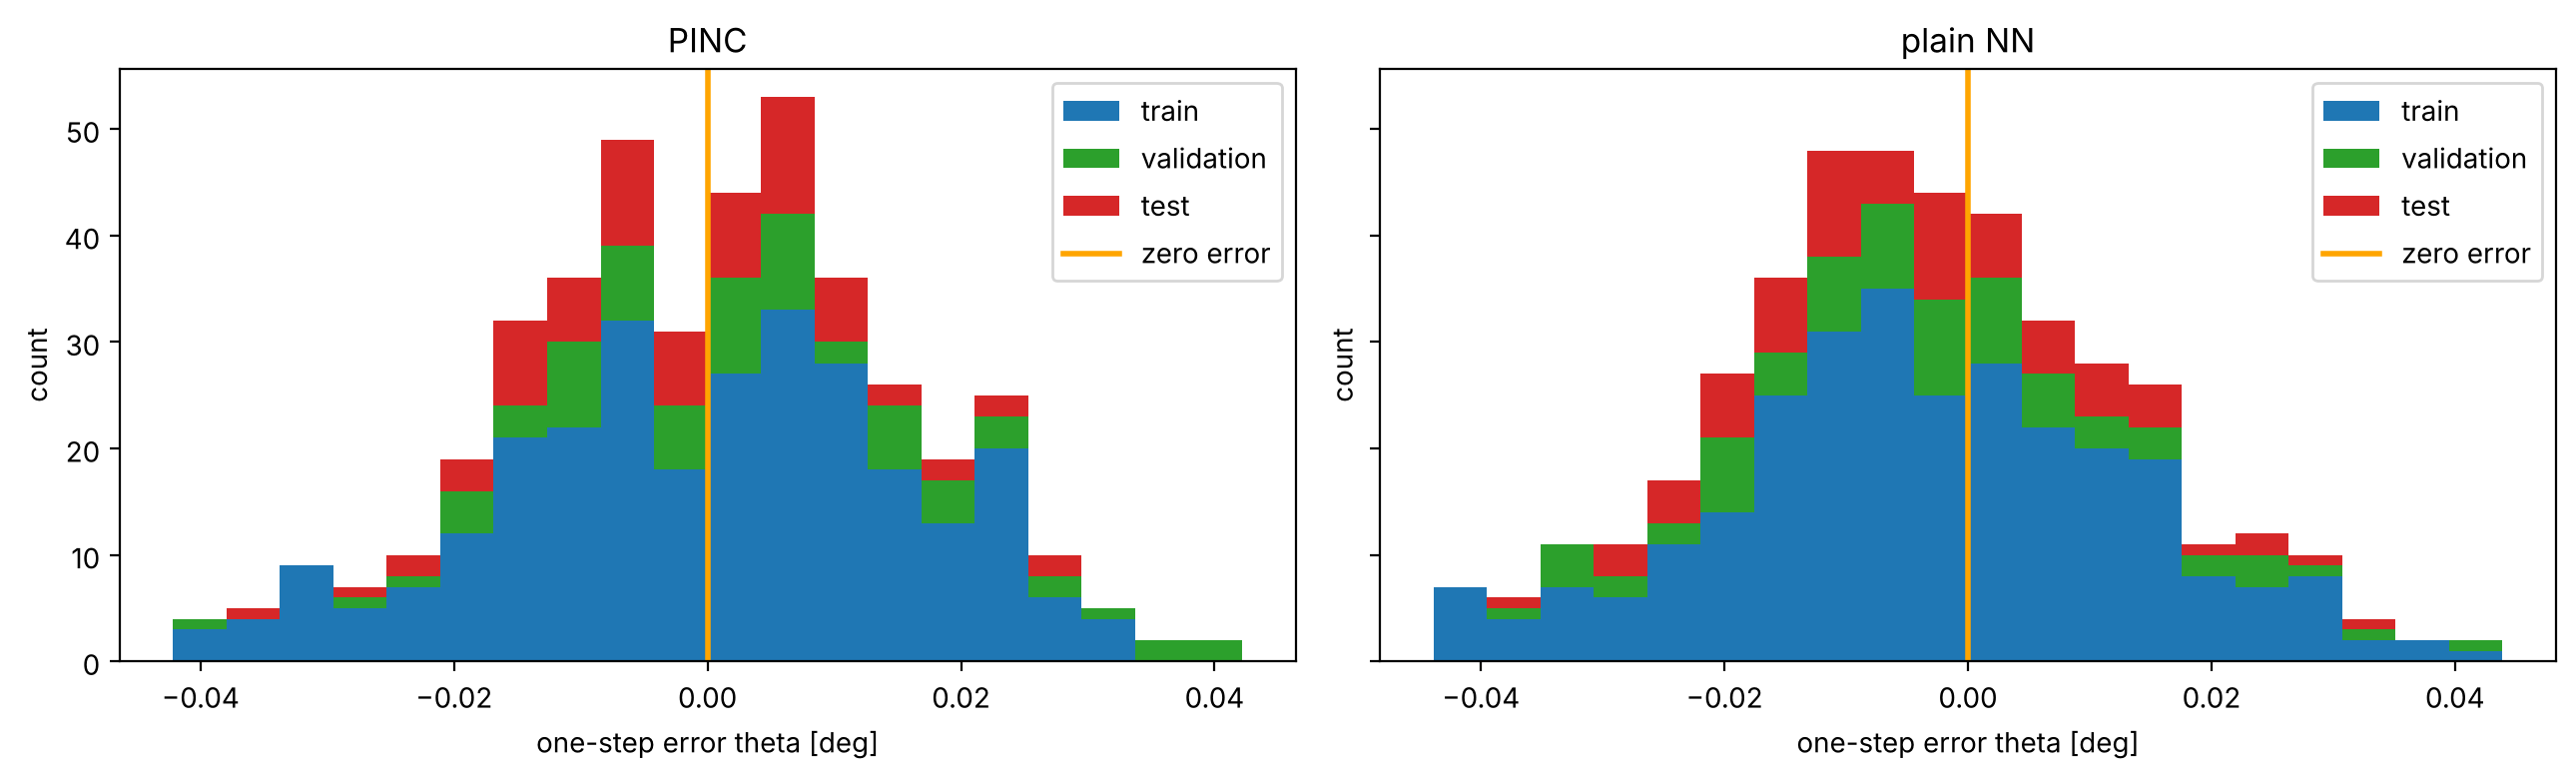

In [11]:
def one_step_errors(st, key):
    a_, b_, m_, a1, _ = st.sets[key]
    with torch.no_grad(): x, _ = st.torch_step(a_, b_, m_, torch.full_like(a_, DT))
    return np.degrees((a1 - x).numpy().ravel())
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, label in zip(ax, ['PINC', 'plain NN']):
    E = [one_step_errors(nets[label], k) for k in ['train', 'validation', 'test']]
    lim = np.percentile(np.abs(np.concatenate(E)), 99); bins = np.linspace(-lim, lim, 21)
    a.hist(E, bins=bins, stacked=True, color=['C0', 'C2', 'C3'], label=['train', 'validation', 'test'])
    a.axvline(0, color='orange', lw=2, label='zero error'); a.set(title=label, xlabel='one-step error theta [deg]', ylabel='count'); a.legend()
plt.tight_layout(); plt.savefig('../figures/batch4_ploterrhist.png', dpi=110, bbox_inches='tight'); plt.show()

### 6c. `plotregression`: model output vs measured target, with R
Each dot is one step: x = measured theta, y = model's theta. How to read: dots on the 45° line and **R close to 1** = good. Here everything is one step ahead, so R is very close to 1 for both; the harder test is the simulation Fit % in section 2.

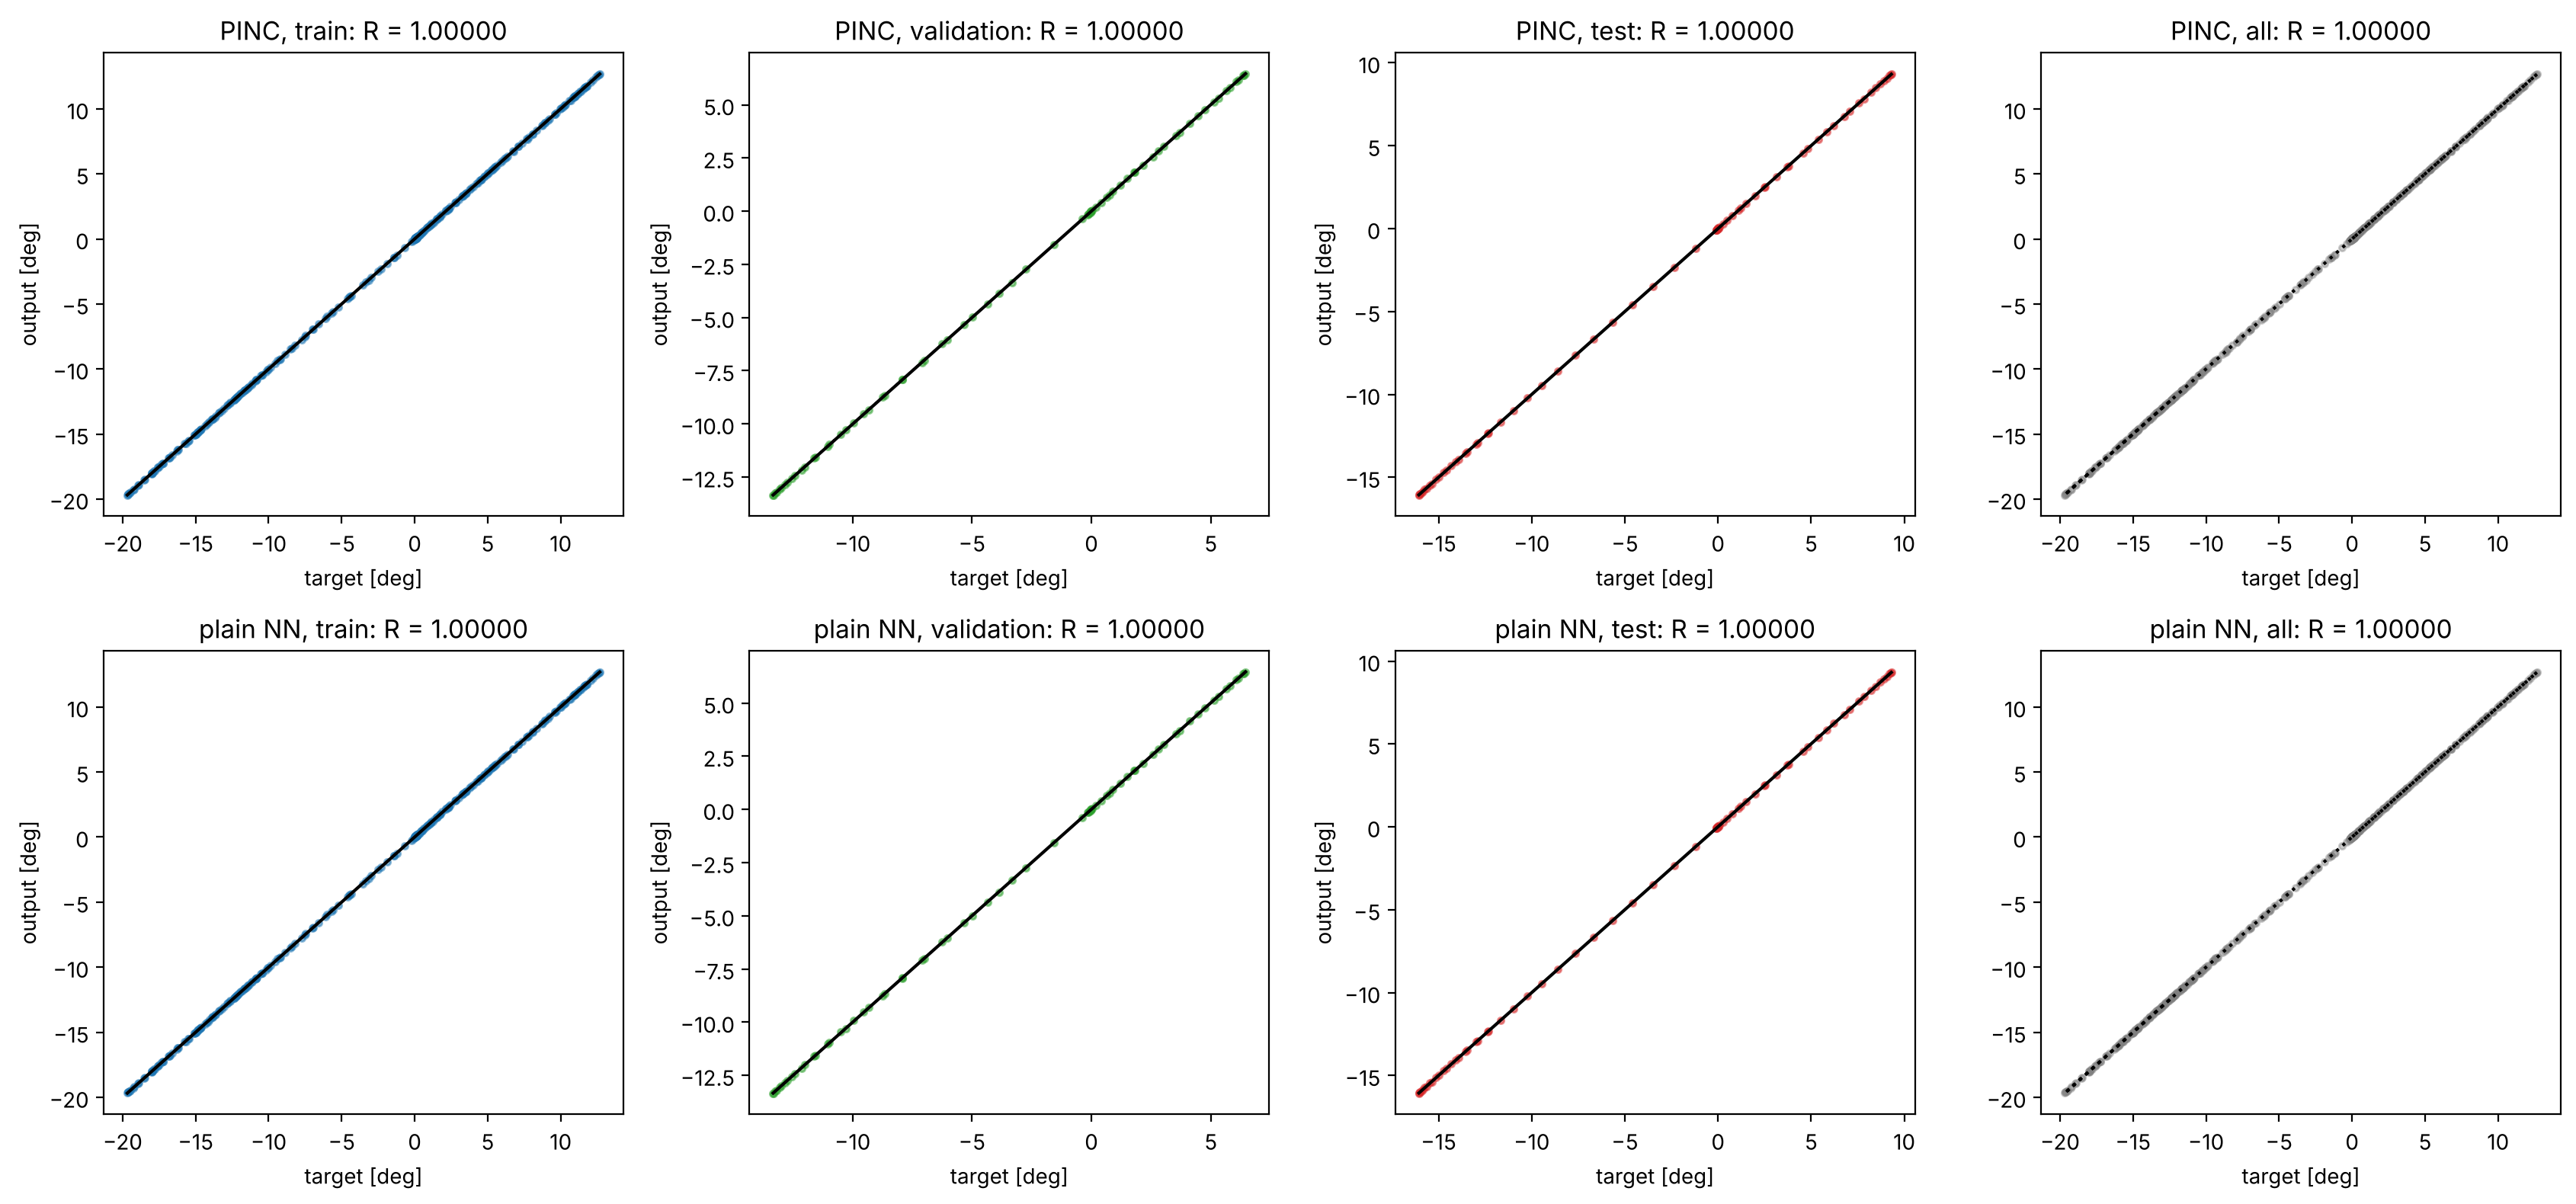

In [12]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8))
for i, label in enumerate(['PINC', 'plain NN']):
    allx, ally = [], []
    for j, k in enumerate(['train', 'validation', 'test']):
        st = nets[label]; a_, b_, m_, a1, _ = st.sets[k]
        with torch.no_grad(): x, _ = st.torch_step(a_, b_, m_, torch.full_like(a_, DT))
        tgt = np.degrees(a1.numpy().ravel()); out = np.degrees(x.numpy().ravel()); allx.append(tgt); ally.append(out)
        R = np.corrcoef(tgt, out)[0, 1]; m, c0 = np.polyfit(tgt, out, 1)
        ax[i, j].plot(tgt, out, 'o', ms=3, alpha=0.5, color=['C0', 'C2', 'C3'][j]); ax[i, j].plot(tgt, tgt, 'k:', lw=1)
        ax[i, j].plot(np.sort(tgt), m * np.sort(tgt) + c0, color='k'); ax[i, j].set(title=f'{label}, {k}: R = {R:.5f}', xlabel='target [deg]', ylabel='output [deg]')
    tgt, out = np.concatenate(allx), np.concatenate(ally); R = np.corrcoef(tgt, out)[0, 1]
    ax[i, 3].plot(tgt, out, 'o', ms=3, alpha=0.4, color='gray'); ax[i, 3].plot(tgt, tgt, 'k:'); ax[i, 3].set(title=f'{label}, all: R = {R:.5f}', xlabel='target [deg]')
plt.tight_layout(); plt.savefig('../figures/batch4_plotregression.png', dpi=100, bbox_inches='tight'); plt.show()

### 6d. The "coloured square matrix": score heatmap
MATLAB's coloured square (`plotconfusion`) is for **classification** (e.g. "is this a cat or a dog"), so it does not apply to our model, which predicts numbers. The same idea for us: a coloured table of **every model x every test score** on the unseen flights. Green = good, red = bad, so the best model per column stands out at a glance.

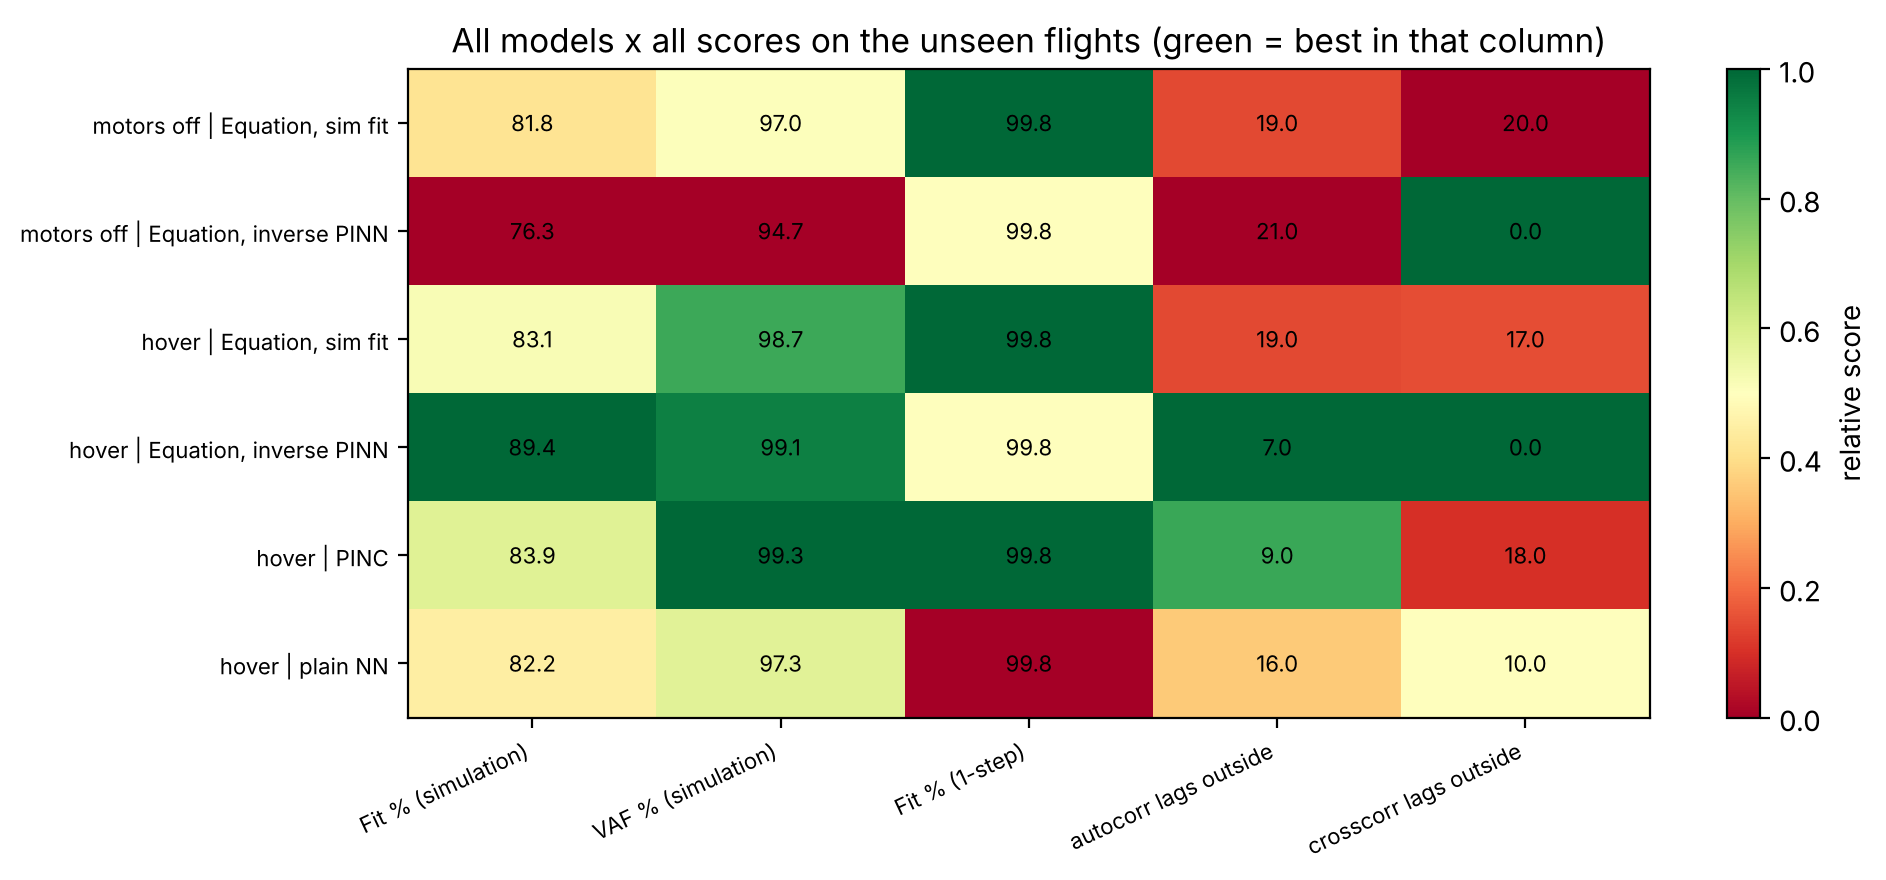

In [13]:
H = t_compare.copy()
H['autocorr lags outside'] = t_resid['autocorr lags outside band (of 25)']
H['crosscorr lags outside'] = t_resid['crosscorr lags >= 0 outside band (of 26)']
Z = H.astype(float).copy()
for c_ in Z.columns:                                     # 1 = best in the column, 0 = worst
    v = Z[c_]; Z[c_] = (v - v.min()) / (v.max() - v.min() + 1e-12)
    if 'outside' in c_: Z[c_] = 1 - Z[c_]
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(Z.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(H.columns))); ax.set_xticklabels(H.columns, rotation=25, ha='right', fontsize=8)
ax.set_yticks(range(len(H.index))); ax.set_yticklabels([f'{a} | {b}' for a, b in H.index], fontsize=8)
for i in range(H.shape[0]):
    for j in range(H.shape[1]): ax.text(j, i, f'{float(H.iloc[i, j]):.1f}', ha='center', va='center', fontsize=8)
ax.set_title('All models x all scores on the unseen flights (green = best in that column)')
plt.colorbar(im, label='relative score'); plt.tight_layout(); plt.savefig('../figures/batch4_heatmap.png', dpi=110, bbox_inches='tight'); plt.show()

## 7. Summary for the report
Read in this order: Fit % (is the model close?), resid (is anything systematic left?), present (are the constants pinned down?), poles/Bode (what the constants mean physically).